# Report2CT inference

Generate a 3D chest CT volume (480 × 480 × 256) from a radiology report (findings + impression).

**Requirements:** a CUDA GPU with ~40 GB memory and the packages in `requirements.txt`. Run this notebook from the repository root.
Sampling 500 steps takes about 1 minute on an H100.

## 1. Download the model weights

Downloads `report2ct_weights.zip` from Google Drive and extracts it into `vlm3D_work_dir/models/` (skipped if the weights are already there).

In [1]:
import os
import zipfile

import gdown

WEIGHTS_URL = "https://drive.google.com/file/d/1JQuGAOQpHrh0lccLATxut9OC5nAi7V11/view?usp=sharing"  # Google Drive link to report2ct_weights.zip

if not os.path.exists("vlm3D_work_dir/models/diff_unet_ckpt_FI_2560_multi_best_inference.pt"):
    gdown.download(WEIGHTS_URL, "report2ct_weights.zip", fuzzy=True)
    zipfile.ZipFile("report2ct_weights.zip").extractall(".")

## 2. Write the report

`spacing` is the voxel spacing (mm) of the generated volume: original spacing × original size / (480, 480, 256).

In [2]:
findings = "Trachea and both main bronchi are open. No occlusive pathology was detected in the trachea and both main bronchi. Peripheral and central consolidations and areas of ground glass are observed in the upper and lower lobes of both lungs and the middle lobe of the right lung. When evaluated together with the clinical information of the patient, these appearances were evaluated primarily in favor of viral pneumonia. The findings described in Covid-19 pneumonia are frequently observed. No mass was detected in both lungs. Mediastinal structures cannot be evaluated optimally because contrast material is not given. As far as can be observed: Heart contour and size are normal. There is no pleural or pericardial effusion. The widths of the mediastinal main vascular structures are normal. No pathologically enlarged lymph nodes were detected in the mediastinum and hilar regions. No pathological wall thickness increase was observed in the esophagus within the sections. No upper abdominal free fluid-collection was detected in the sections. No enlarged lymph nodes in pathological dimensions were detected. In the upper abdominal organs within the sections, there is no mass with distinguishable borders as far as it can be observed within the borders of non-enhanced CT. Thoracic vertebral corpus heights, alignments and densities are normal. Intervertebral disc distances are preserved. The neural foramina are open. No lytic-destructive lesions were detected in the bone structures within the sections."
impression = "Findings consistent with viral pneumonia in both lungs."
spacing = (0.87, 0.87, 1.35)  # e.g. a 1024 x 1024 x 231 scan at 0.406 x 0.406 x 1.5 mm

## 3. Encode the report

The three text encoders (MedEmbed, ClinicalBERT, CXR-BERT) are downloaded from Hugging Face on first use.

In [3]:
import torch

from inference import ReportEncoder, generate_ct, load_report2ct, save_ct

device = torch.device("cuda")

encoder = ReportEncoder(device)
context = encoder.encode_report(findings, impression)  # (1, 2, 2560): [findings, impression]
del encoder
torch.cuda.empty_cache()

## 4. Load Report2CT and generate the CT

In [4]:
model_args, autoencoder, unet, scale_factor = load_report2ct(device)

In [5]:
volume = generate_ct(model_args, autoencoder, unet, scale_factor, context, spacing, num_inference_steps=500, seed=2045)
save_ct(volume, spacing, "outputs/report2ct_sample.nii.gz")
print(volume.shape, volume.dtype)

(480, 480, 256) int16


## 5. View the result

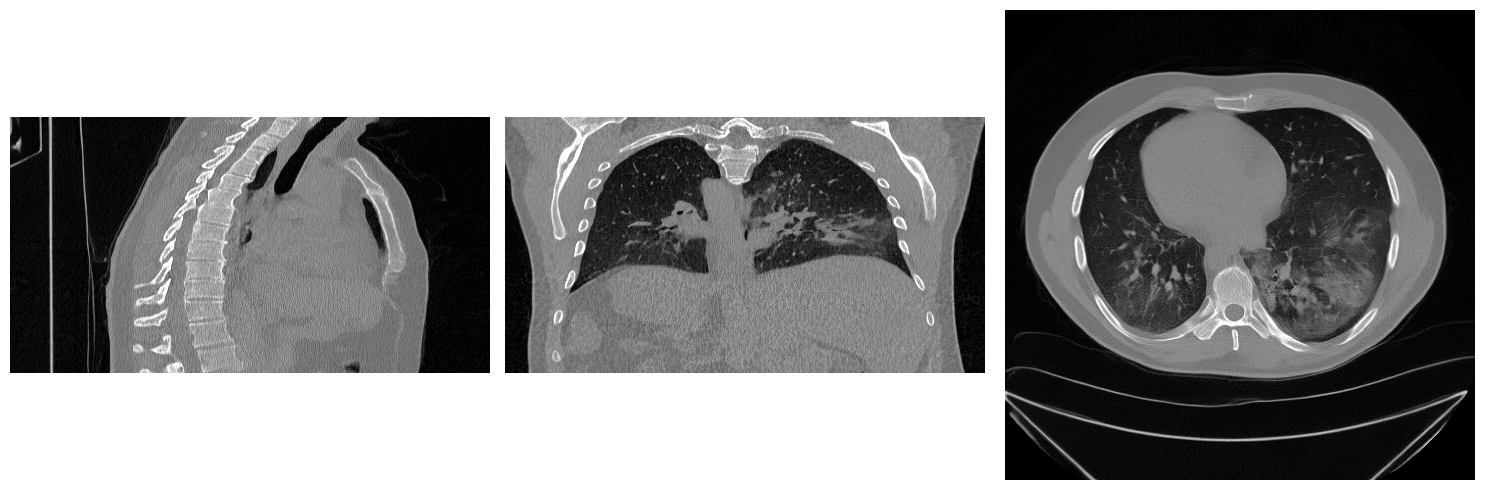

In [6]:
import matplotlib.pyplot as plt
import numpy as np

x, y, z = (s // 2 for s in volume.shape)
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, view in zip(axs, [volume[x], volume[:, y], volume[:, :, z]]):
    ax.imshow(np.rot90(view), cmap="gray")
    ax.axis("off")
plt.tight_layout()
plt.show()